# HW1 — Item 1: Standard deviation

This item compares **NumPy's** standard deviation with the estimator sheet.

The sample mean is $\bar{x} = \frac{1}{N}\sum_{i=1}^{N} x_i$

In [1]:
import numpy as np

This homework requires random 100 numbers to calculate standard deviations. To make our objective of comparing numpy's standard deviation with lecture 2 slide's formula's we choose a normal distribution with known standard deviation and mean. 
note: we use seed of "2026" for reproducibility purposes

In [2]:
rng = np.random.default_rng(2026)
a = rng.normal(10,2,100)

we check if the array consists 100 numbers and we generate first 5 numbers just to see

In [3]:
print(a.shape)     
print(a[:5])       

(100,)
[ 8.41375505 10.48114257  6.2073473  12.79154342 11.27658948]


We calculate standard deviation with N and N-1 by changing the ddof value from default "0" to "1".

In [4]:
std_pop    = a.std()
std_sample = a.std(ddof=1)

In [5]:
print(f"std()       = {std_pop:.6f}")
print(f"std(ddof=1) = {std_sample:.6f}")

std()       = 2.036969
std(ddof=1) = 2.047231


## Implementation

I implement the estimator from the Lecture 2 sheet:

$s^2 = \frac{1}{N-1}\sum_{i=1}^{N}(x_i - \bar{x})^2$,  $s = \sqrt{s^2}$

In [6]:
N = a.size
x_bar = a.sum()/N
dev = a - x_bar
sq = dev**2
ss = sq.sum()
s2 = ss/(N-1)
std_mine = np.sqrt(s2)


## Comparison


In [7]:
print(f"NumPy std()       : {std_pop:.6f}")
print(f"NumPy std(ddof=1) : {std_sample:.6f}")
print(f"My implementation : {std_mine:.6f}")

NumPy std()       : 2.036969
NumPy std(ddof=1) : 2.047231
My implementation : 2.047231


We conclude from these results that standard deviation with "ddof=1" is identical to our implementation. 
This is due to the fact that in original std function, we divide sum of squared deviations by N whereas in the "ddof=1" version we divided it by N-1. This is called Bessel's correction and is necessary to prevent underestimation of the spread.


## Item 2 — Binning random numbers

In [8]:
import numpy as np

rng = np.random.default_rng(seed=10)         

u = rng.random(10000)                           
z = rng.normal(0, 1, size=10000)          

print(u.shape, z.shape)
print(u.min(), u.max())
print(z.min(), z.max())

(10000,) (10000,)
0.00010989257915827721 0.9998496314151111
-3.642558404047101 3.4328260571782128


We created a seeded generator. "u" is an array of random 10000 numbers that is drawn from a uniform distribution. "z" is an array of random 10000 numbers that is drawn from a normal distribution. As can be seen both have size (10000, ). We also checked the max and min values to verify. 

Before we continue, we must decide on edge selection as it is critical. We have both normal and uniform distribution. If we select the same edges,
There can be problems as in normal distribution 34% of the values lies within [0,1) range. For this reason, we will chose different edges.

For the start, We use "K=10" bins. 

In [9]:
K = 10
edges_u = np.linspace(0, 1, K + 1)     
edges_z = np.linspace(-4, 4, K + 1)     
print(edges_u)
print(edges_z)

[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
[-4.  -3.2 -2.4 -1.6 -0.8  0.   0.8  1.6  2.4  3.2  4. ]


We see that for 10 bins, we get 11 numbers as expected. We will use the convention of [lo,hi) from the lecture slides. 
note: We picked min and max values for normal as -4 and 4 to observe the symmetric nature of the distribution. We picked 0 and 1 for uniform distribution as all the numbers is in this range from definition. 

In [10]:
u_below = ( u < edges_u[0] ).sum()     
u_above = ( u >= edges_u[-1] ).sum()     
print(u_below, u_above)

z_below = ( z < edges_z[0] ).sum()     
z_above = ( z >= edges_z[-1] ).sum()     
print(z_below, z_above)

0 0
0 0


We see that outside of our edges, there are no numbers. We also included the ,hi) value in the code to see whether any number is left behind due to our convention of [lo,hi).

In [11]:
def my_bin_counts(data, edges):
    
    K = len(edges) - 1                        
    counts = np.zeros(K, dtype=int)
    for k in range(K):
        lo = edges[k]
        hi = edges[k + 1]
        mask = (data >= lo) & (data < hi)                   
        counts[k] = mask.sum()             
    return counts

We define a function that returns an array of numbers. This array tells us how many numbers are present at each bin. 
    It can be seen that "data<hi" is written. This is intentional as we discussed our convention previously. We exclude higher bound of each bin. 

In [12]:

test_data  = np.array([0.5, 12, 26.9, 27, 37, 99.9, 100, -3])
test_edges = np.array([0, 12, 27, 37, 100])
print(my_bin_counts(test_data, test_edges))
print(np.histogram(test_data, bins=test_edges)[0])


counts_u = my_bin_counts(u, edges_u)
counts_z = my_bin_counts(z, edges_z)
print(counts_u, counts_u.sum())
print(counts_z, counts_z.sum())

[1 2 1 2]
[1 2 1 3]
[ 959 1002  990 1037 1003 1022  938 1035 1021  993] 10000
[   7   92  485 1542 2786 2954 1567  476   87    4] 10000


We compare np.histogram with our own function by testing them on a small and observable test data. Then, we do it for our real data and from the returned counts for both "u" and "z", we see that their sums are exactly 10000. This shows that our conclusion from before(there are no numbers outside our bins) is true. We also observed that for np.histogram, last edge is included and the number count is "3" instead of "2". The difference comes from np.histogram closing its last bin; our function follows the [lo, hi) convention throughout.
    

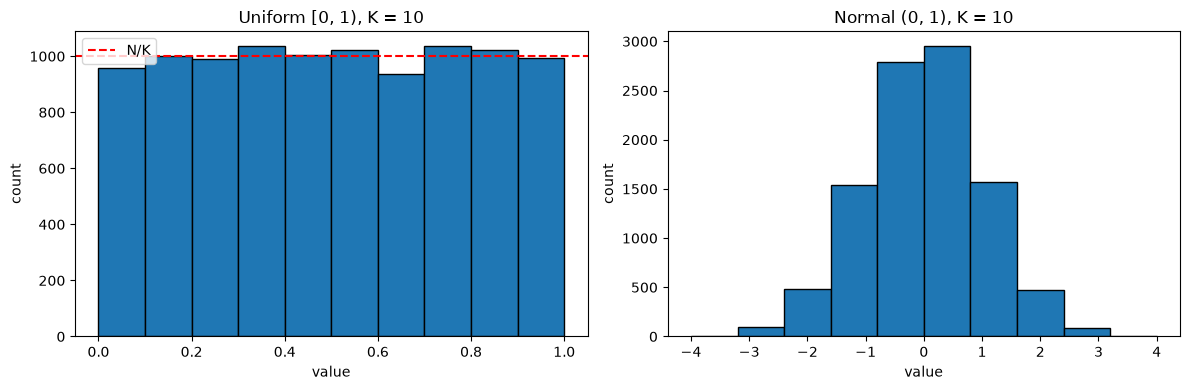

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))     

axes[0].bar(edges_u[:-1], counts_u, width=np.diff(edges_u), align='edge', edgecolor='black')
axes[0].axhline(len(u) / (len(edges_u) - 1), color='red', linestyle='--', label='N/K')
axes[0].set_title('Uniform [0, 1), K = 10')
axes[0].set_xlabel('value')
axes[0].set_ylabel('count')
axes[0].legend()

axes[1].bar(edges_z[:-1], counts_z, width=np.diff(edges_z), align='edge', edgecolor='black')
axes[1].set_title('Normal (0, 1), K = 10')
axes[1].set_xlabel('value')
axes[1].set_ylabel('count')

plt.tight_layout()
plt.show()

We plot these two binned arrays. As it can be seen, their characteristic distributions are visible(normal and uniform) but these do not exactly represent their distribution perfectly. This is due to the noise that is present(1/√(N·p)). This is not a problem as we expected noise. Binning sets the resolution (a staircase instead of a smooth curve), while finite N causes the random deviations

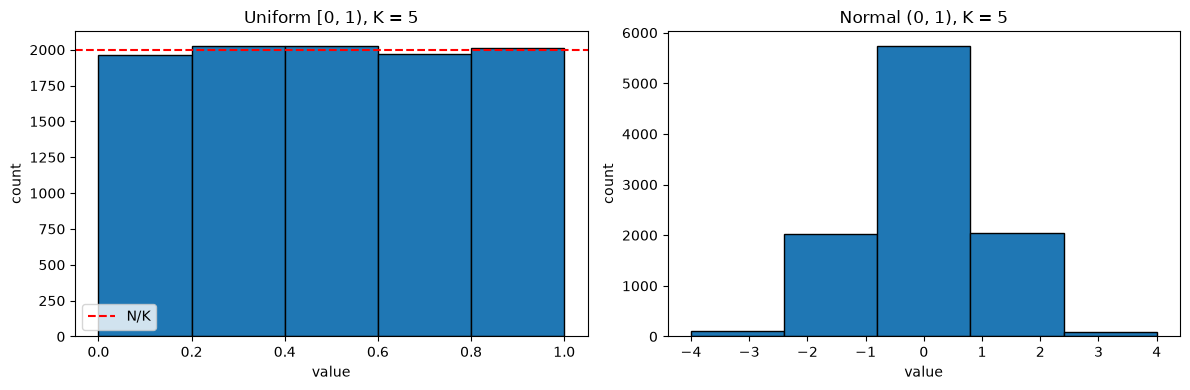

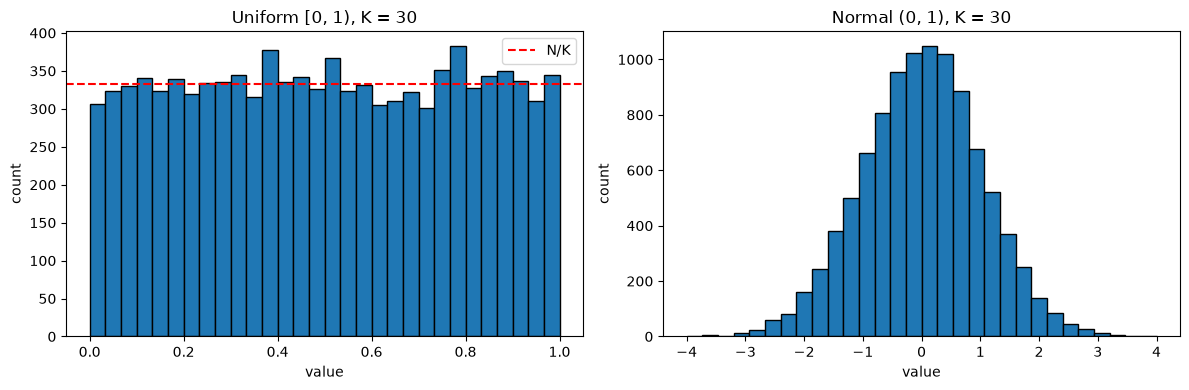

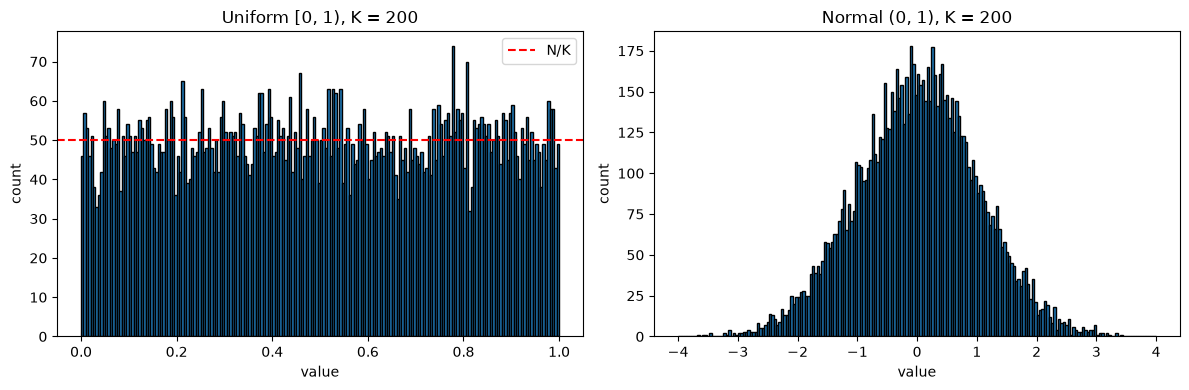

In [14]:
def bin_and_plot(K):
    edges_u = np.linspace(0, 1, K + 1)     
    counts_u = my_bin_counts(u, edges_u)
    edges_z = np.linspace(-4, 4, K + 1)     
    counts_z = my_bin_counts(z, edges_z)
    

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))     
    
    axes[0].bar(edges_u[:-1], counts_u, width=np.diff(edges_u), align='edge', edgecolor='black')
    axes[0].axhline(len(u) / (len(edges_u) - 1), color='red', linestyle='--', label='N/K')
    axes[0].set_title(f'Uniform [0, 1), K = {K}')
    axes[0].set_xlabel('value')
    axes[0].set_ylabel('count')
    axes[0].legend()
    
    axes[1].bar(edges_z[:-1], counts_z, width=np.diff(edges_z), align='edge', edgecolor='black')
    axes[1].set_title(f'Normal (0, 1), K = {K}')
    axes[1].set_xlabel('value')
    axes[1].set_ylabel('count')
    
    plt.tight_layout()
    plt.show()

for K in [5, 30, 200]:
    bin_and_plot(K) 

Uniform looks flat with every bin near N/K and Normal looks like a bell curve that is symmetric that peaks at zero with small tails. With few bins (K = 5) normal is only 5-steps which is too coarse. With many bins (K = 200) we see a more characteristic curve but noise increases, because each bin holds fewer points (N/K), and the relative noise grows like √(K/N): about 2% at K = 5 versus 14% at K = 200. We observe that K ≈ 30 gives the best balance.

## Item 3 — RMSE function

In [15]:
def rmse(y_hat, y):
    
    y_hat = np.asarray(y_hat, dtype=float)
    y = np.asarray(y, dtype=float)
    if y_hat.shape != y.shape:
        raise ValueError(f"Shape mismatch: y_hat {y_hat.shape} vs y {y.shape}")
    return np.sqrt(np.mean((y_hat - y) ** 2))

We convert y_hat and y to float arrays for precaution purposes(in the future, a python list may be passed to this function).
Then we check the shapes and raise error if they don't match. If they match, the function returns the RMSE. 

In [16]:
import numpy as np
y_test = np.array([1.0, 2.0, 3.0, 4.0])

print("perfect prediction:", rmse(y_test, y_test))       # expect 0.0
print("constant offset 3 :", rmse(y_test + 3, y_test))   # expect 3.0

try:
    rmse(np.array([1.0, 2.0]), y_test)                   # wrong length
except ValueError as e:
    print("shape check works:", e)

perfect prediction: 0.0
constant offset 3 : 3.0
shape check works: Shape mismatch: y_hat (2,) vs y (4,)


We conduct a test with known answers beforehand.

In [17]:
rng = np.random.default_rng(1)
data = rng.normal(50, 10, 10_000)      
rng.shuffle(data)                      
splits = np.array_split(data, 5)      

print(f"{'split':>5} {'my rmse':>9} {'one-liner':>10} {'std':>9} {'std ddof=1':>11}")
for k, part in enumerate(splits):
    y_hat  = np.full_like(part, part.mean())             
    r_mine = rmse(y_hat, part)
    r_demo = np.sqrt(np.mean((part.mean() - part) ** 2))  
    s_pop  = np.std(part)                                 
    s_samp = np.std(part, ddof=1)                         
    print(f"{k:>5} {r_mine:>9.4f} {r_demo:>10.4f} {s_pop:>9.4f} {s_samp:>11.4f}")

split   my rmse  one-liner       std  std ddof=1
    0    9.7321     9.7321    9.7321      9.7346
    1   10.0384    10.0384   10.0384     10.0409
    2   10.0968    10.0968   10.0968     10.0994
    3    9.9924     9.9924    9.9924      9.9949
    4   10.0561    10.0561   10.0561     10.0586


We generate a seeded rng and we define a normal distribution with mean = 50 and std = 10. Then we shuffle the data. After that, we split the data into 5 pieces so every piece gives arrays of 2000 values.
Then we make the array same shape as part with its mean. 
We observe that in the output, first three columns return the same values. This is due to the fact that we picked ŷ = mean and in result the RMSE formula gives standard deviation with factor 1/n so it matches np.std with ddof=0. In column four, we see a different number, this is due to Bessel's correction. 
It can also be observed that all values are around 10. This is due to our choice of std=10. In conclusion, we predicted the mean and only recovered 
the noise level (std=10). That is the noise floor, which no model can beat. 
    

# Item 4 — Data collection exercise

## 4.1 Problem and table sketch
**Problem:** Predict the compressive strength of concrete from its mix proportions and its age.
This matters because strength is only known after days of curing and a destructive test;
a model could screen mix designs before casting.

**One row per:** one compressive-strength test of one concrete mix at one age.
Note: the same mix can appear at several ages → rows are *not* fully independent.

| Column | Type | Unit | Role |
|---|---|---|---|
| cement | numerical, continuous | kg/m³ | feature |
| slag (blast furnace slag) | numerical, continuous | kg/m³ | feature |
| fly_ash | numerical, continuous | kg/m³ | feature |
| water | numerical, continuous | kg/m³ | feature |
| superplasticizer | numerical, continuous | kg/m³ | feature |
| coarse_agg | numerical, continuous | kg/m³ | feature |
| fine_agg | numerical, continuous | kg/m³ | feature |
| age_days | numerical, discrete | day | feature |
| strength_MPa | numerical, continuous | MPa | **target** |

## 4.2 Source
**Database** : UCI Machine Learning Repository,
"Concrete Compressive Strength", I-Cheng Yeh (1998), DOI 10.24432/C5PK67, licence CC BY 4.0.
Original study: I-C. Yeh, *Cement and Concrete Research* 28(12), 1798–1808 (1998).
Downloaded: 2 November 2026. Raw files kept unchanged in `raw/`.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Load — first three calls on any new table: shape, head(), dtypes 
`raw` is never modified; all cleaning happens on the copy `df`.

In [19]:
raw = pd.read_excel('./raw/Concrete_Data.xls')
df = raw.copy()

print(raw.shape)
print(raw.columns.tolist())

(1030, 9)
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) ']


In [20]:
raw.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [21]:
raw.dtypes

Cement (component 1)(kg in a m^3 mixture)                float64
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    float64
Fly Ash (component 3)(kg in a m^3 mixture)               float64
Water  (component 4)(kg in a m^3 mixture)                float64
Superplasticizer (component 5)(kg in a m^3 mixture)      float64
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     float64
Fine Aggregate (component 7)(kg in a m^3 mixture)        float64
Age (day)                                                  int64
Concrete compressive strength(MPa, megapascals)          float64
dtype: object

## 4.3 Cleanup 

### (4) Improper format: the header
The original column names contain the unit, a component number, double spaces
(`'Water  (component 4)...'`, `'Coarse Aggregate  (component 6)...'`) and a trailing space
(`'...megapascals) '`). They are hard to type and a single missing space gives a KeyError.
**Decision:** rename to short names; the units move to the metadata file

Renaming is done by position, after checking there are exactly 9 columns in the documented order.

Also visible in `head()`: rows 2 and 3 are the same mix tested at 270 and 365 days —
the same mix appears at several ages.

In [22]:
assert raw.shape[1] == 9, "unexpected number of columns - check the file"

new_names = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
             'coarse_agg', 'fine_agg', 'age_days', 'strength_MPa']
df.columns = new_names
df.describe()

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age_days,strength_MPa
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


### (1) Incorrect: impossible values and a physics check
- Masses and strength cannot be negative.
- Physics check : the components of 1 m³ of concrete should add up
  to roughly the density of concrete, about 2200–2500 kg/m³. Rows far outside are
  **flagged, not deleted**, unless a cause is found.

negative values: 0
count    1030.000000
mean     2343.515199
std        65.362861
min      2194.600000
25%      2291.150000
50%      2349.000000
75%      2390.270000
max      2551.000000
Name: total_kg_m3, dtype: float64
0 rows outside 2100-2600 kg/m3


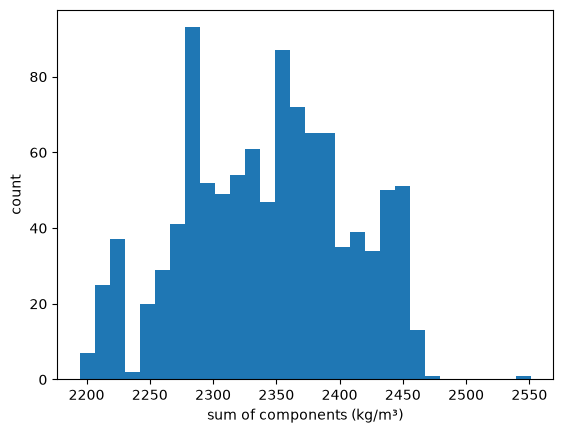

In [23]:
print('negative values:', (df < 0).sum().sum())

components = new_names[:7]
df['total_kg_m3'] = df[components].sum(axis=1)
print(df['total_kg_m3'].describe())

suspicious = df[(df['total_kg_m3'] < 2100) | (df['total_kg_m3'] > 2600)]
print(len(suspicious), 'rows outside 2100-2600 kg/m3')

plt.hist(df['total_kg_m3'], bins=30)
plt.xlabel('sum of components (kg/m³)')
plt.ylabel('count')
plt.show()

In [24]:
df[df['total_kg_m3'] > 2500]

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age_days,strength_MPa,total_kg_m3
69,485.0,0.0,0.0,146.0,0.0,1120.0,800.0,28,71.988189,2551.0


**Result:** no negative values. The components sum to 2194.6–2551.0 kg/m³ (mean 2343.5),
the normal density range of concrete, so **0 rows are flagged** and none is removed at this step.
One mix (~2551 kg/m³) sits apart from the rest in the histogram, but it is still physically plausible:
So it is **kept**.

### (2) Incomplete: missing values and the meaning of zero
`isnull()` finds NaN. But many rows have **0** for slag, fly ash or superplasticizer
(their 25 % value in `describe()` is already 0).
Unlike the 30 °C in the fatigue data (a sentinel for "not done"), **0 kg/m³ here is a true physical value**:
the component was not added, and "zero added" is exactly what the number says.
**Decision:** keep the zeros as numbers; do not replace them with NaN.

In [25]:
print(df.isnull().sum())
for c in ['slag', 'fly_ash', 'superplasticizer']:
    print(f"{c}: {(df[c] == 0).mean():.0%} of rows are 0")

cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_agg          0
fine_agg            0
age_days            0
strength_MPa        0
total_kg_m3         0
dtype: int64
slag: 45% of rows are 0
fly_ash: 55% of rows are 0
superplasticizer: 37% of rows are 0


In [26]:
n_dup = df.duplicated(subset=new_names).sum()
print(n_dup, 'exact duplicate rows')
df[df.duplicated(subset=new_names, keep=False)].sort_values(new_names).head(10)

25 exact duplicate rows


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age_days,strength_MPa,total_kg_m3
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435,2332.0
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435,2332.0
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171,2428.6
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171,2428.6
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171,2428.6
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171,2428.6
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819,2428.6
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819,2428.6
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819,2428.6
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713,2428.6


In [27]:
df = df.drop_duplicates(subset=new_names).reset_index(drop=True)
print('after dropping:', df.shape)

after dropping: (1005, 10)


**Result:** 25 exact duplicate rows were found and dropped (1030 → 1005 rows).
They come in groups: e.g. rows 83, 86, 88 and 91 are the same mix at the same age (3 days) with the same strength
to six decimals (35.301171 MPa). Independent replicate tests cannot agree to 0.000001 MPa, so these are either
copied entries or one averaged value repeated. Keeping them would give these mixes 2–4× more weight in a fit
than the others. Which explanation is correct is not stated in the source (→ 4.6).

### Structure check: how many distinct mixes?
Same mix proportions at different ages = one mix tested several times (a short time series per mix)
A `mix_id` lets a later train/test split keep all ages of one mix together; otherwise the test set would contain
mixes the model already saw (leakage).

In [28]:
df['mix_id'] = df.groupby(components).ngroup()
print(df['mix_id'].nunique(), 'distinct mixes in', len(df), 'rows')
print('ages per mix:')
print(df.groupby('mix_id').size().value_counts().sort_index())
print('ages tested:', sorted(df['age_days'].unique()))

428 distinct mixes in 1005 rows
ages per mix:
1    246
2     42
3      7
4     38
5     77
6     12
7      3
8      3
Name: count, dtype: int64
ages tested: [np.int64(1), np.int64(3), np.int64(7), np.int64(14), np.int64(28), np.int64(56), np.int64(90), np.int64(91), np.int64(100), np.int64(120), np.int64(180), np.int64(270), np.int64(360), np.int64(365)]


### A first descriptor and a physics sanity check 
Abrams' law: strength falls as the **water-to-cement ratio** w/c rises. If the data are physical, the scatter should
show this trend, with older specimens stronger at the same w/c. `scatter`, not `plot`: rows are independent samples.

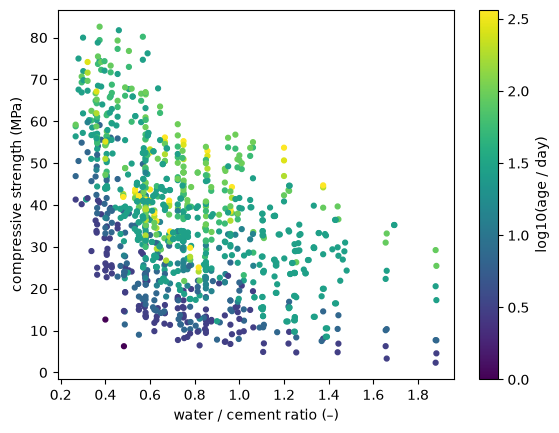

In [29]:
df['w_c'] = df['water'] / df['cement']

sc = plt.scatter(df['w_c'], df['strength_MPa'], c=np.log10(df['age_days']), s=12, cmap='viridis')
plt.colorbar(sc, label='log10(age / day)')
plt.xlabel('water / cement ratio (–)')
plt.ylabel('compressive strength (MPa)')
plt.show()

**Result (structure):** 1005 rows come from only **428 distinct mixes**. 246 mixes were tested at one age;
182 mixes were tested at 2–8 ages and make up 759 rows (~76 %). 14 ages from 1 to 365 days.
→ The rows are not independent: the effective number of samples is closer to 428 than to 1005,
and any future train/test split must keep all ages of a mix on the same side (split by `mix_id`).

**Result (physics):** strength falls as w/c rises (≈ 60–80 MPa at w/c ≈ 0.3, < 35 MPa at w/c ≈ 1.8),
and at the same w/c older specimens are stronger. Both agree with Abrams' law and with curing,
so the data behave physically. At fixed w/c and age the spread is still ~20–30 MPa, so the other
components (slag, fly ash, superplasticizer) must matter too.

### Save the processed data
`total_kg_m3` was only a check and is removed; `mix_id` and `w_c` are kept as derived columns.

In [30]:
del df['total_kg_m3']
df.to_csv('./processed/concrete_clean.csv', index=False)
print('saved', df.shape)

saved (1005, 11)


## 4.4 Metadata file next to the data 

In [31]:
%%writefile metadata.yaml
dataset: Concrete compressive strength vs mix proportions and age
source:
  repository: UCI Machine Learning Repository
  name: Concrete Compressive Strength
  creator: I-Cheng Yeh
  doi: 10.24432/C5PK67
  licence: CC BY 4.0
  original_paper: "Yeh, I-C. (1998) Cement and Concrete Research 28(12)"
  downloaded: 2026-11-02
raw_files: [raw/Concrete_Data.xls, raw/Concrete_Readme.txt]
row_definition: one compressive-strength test of one mix at one age
columns:
  cement:           {unit: kg/m3, type: float}
  slag:             {unit: kg/m3, type: float, note: "0 = not added (true value)"}
  fly_ash:          {unit: kg/m3, type: float, note: "0 = not added (true value)"}
  water:            {unit: kg/m3, type: float}
  superplasticizer: {unit: kg/m3, type: float, note: "0 = not added (true value)"}
  coarse_agg:       {unit: kg/m3, type: float}
  fine_agg:         {unit: kg/m3, type: float}
  age_days:         {unit: day, type: int}
  strength_MPa:     {unit: MPa, type: float, role: target}
  mix_id:           {unit: "-", type: int, note: "derived; identical mix proportions share an id"}
  w_c:              {unit: "-", type: float, note: "derived; water / cement"}
missing_value: none in source (NaN would be used)
unknown:
  - test standard, specimen geometry, curing conditions are not given in the source
  - whether duplicate rows are double entries or replicates
  - duplicates come in groups with identical strength to 6 decimals: copies or averaged values?  
processing: raw/Concrete_Data.xls -> HW1 notebook, item 4 -> processed/concrete_clean.csv

Overwriting metadata.yaml


In [32]:
%%writefile .gitignore
.ipynb_checkpoints/
__pycache__/

Overwriting .gitignore


## 4.5 Repository
https://github.com/royyckl2682/hw1-concrete

Structure: `raw/` (untouched download), `processed/` (cleaned CSV), `scripts/`, `metadata.yaml`, this notebook.
Commit 1 (`1d1d335`) contains only the raw data, so every processed number can be traced back to the original file.

## 4.6 Obstacles and open questions
The header mixed units, component numbers, double spaces and a trailing space, so I renamed the columns by position
and moved the units into the metadata file. The source has no missing values and no negative values, and all
mixes pass the density check (2195–2551 kg/m³). But 25 exact duplicate rows had to be dropped (1030 → 1005), and they
come in groups with identical strength to six decimals — nothing in the source says whether they are copied entries
or one averaged value repeated. Zeros in slag (45 % of rows), fly ash (55 %) and superplasticizer (37 %) looked like
a possible sentinel, but here they are true amounts. Important metadata is missing: the test standard, specimen size
and curing conditions, so I cannot check whether all tests are comparable. The 1005 rows come from only 428 mixes
tested at up to 8 ages, so the rows are not independent and any future split must be done by `mix_id`.
Setting up Git and GitHub for the first time was itself an obstacle: A missing quotation mark in git config left the terminal waiting for input, and the project folder was not where File Explorer’s Documents pointed.

# Item 5 — Data exploration exercise: NIMS steel fatigue dataset
Source: NIMS MatNavi via Kaggle (chaozhuang/steel-fatigue-strength-prediction);
Agrawal et al., IMMI 3, 90–108 (2014).
Target `Fatigue`: rotating-bending fatigue strength at 10⁷ cycles, MPa.

**Goal:** decide which descriptors to use for a linear regression of `Fatigue` — by looking, before fitting anything.

### Step 1 — load and inspect: shape, head(), dtypes, describe(), isnull().sum()

In [33]:
df = pd.read_csv('./raw/Fatigue_data.csv')
df.shape

(437, 27)

In [34]:
df.head()

,Sl. No.,NT,THT,THt,THQCr,CT,Ct,DT,Dt,QmT,...,S,Ni,Cr,Cu,Mo,RedRatio,dA,dB,dC,Fatigue
0,1,885,30,0,0,30,0.0,30.0,0.0,30,...,0.022,0.01,0.02,0.01,0.0,825,0.07,0.02,0.04,232
1,2,885,30,0,0,30,0.0,30.0,0.0,30,...,0.017,0.08,0.12,0.08,0.0,610,0.11,0.00,0.04,235
2,3,885,30,0,0,30,0.0,30.0,0.0,30,...,0.015,0.02,0.03,0.01,0.0,1270,0.07,0.02,0.00,235
3,4,885,30,0,0,30,0.0,30.0,0.0,30,...,0.024,0.01,0.02,0.01,0.0,1740,0.06,0.00,0.00,241
4,5,885,30,0,0,30,0.0,30.0,0.0,30,...,0.022,0.01,0.02,0.02,0.0,825,0.04,0.02,0.00,225


In [35]:
df.dtypes

Sl. No.       int64
NT            int64
THT           int64
THt           int64
THQCr         int64
CT            int64
Ct          float64
DT          float64
Dt          float64
QmT           int64
TT            int64
Tt            int64
TCr         float64
C           float64
Si          float64
Mn          float64
P           float64
S           float64
Ni          float64
Cr          float64
Cu          float64
Mo          float64
RedRatio      int64
dA          float64
dB          float64
dC          float64
Fatigue       int64
dtype: object

`Sl. No.` is a row counter, not a property of the steel → irrelevant. Removed.

In [36]:
del df['Sl. No.']
df.shape

(437, 26)

In [37]:
df.describe()

,NT,THT,THt,THQCr,CT,Ct,DT,Dt,QmT,TT,...,S,Ni,Cr,Cu,Mo,RedRatio,dA,dB,dC,Fatigue
count,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,...,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000,437.000000
mean,872.299771,737.643021,25.949657,10.654462,128.855835,40.502059,123.699844,4.843936,35.491991,536.842105,...,0.014611,0.517048,0.570458,0.067780,0.069794,923.629291,0.047181,0.003391,0.007712,552.903890
std,26.212073,280.036541,10.263824,7.841437,281.743539,126.924697,267.128933,15.700076,19.419277,164.101963,...,0.006145,0.852976,0.411769,0.049161,0.088124,576.617020,0.031093,0.008240,0.010418,186.630528
min,825.000000,30.000000,0.000000,0.000000,30.000000,0.000000,30.000000,0.000000,30.000000,30.000000,...,0.003000,0.010000,0.010000,0.010000,0.000000,240.000000,0.000000,0.000000,0.000000,225.000000
25%,865.000000,845.000000,30.000000,8.000000,30.000000,0.000000,30.000000,0.000000,30.000000,550.000000,...,0.010000,0.020000,0.120000,0.020000,0.000000,590.000000,0.020000,0.000000,0.000000,448.000000
50%,870.000000,845.000000,30.000000,8.000000,30.000000,0.000000,30.000000,0.000000,30.000000,600.000000,...,0.015000,0.060000,0.710000,0.060000,0.000000,740.000000,0.040000,0.000000,0.000000,505.000000
75%,870.000000,855.000000,30.000000,8.000000,30.000000,0.000000,30.000000,0.000000,30.000000,650.000000,...,0.019000,0.460000,0.980000,0.100000,0.170000,1228.000000,0.070000,0.000000,0.010000,578.000000
max,930.000000,865.000000,30.000000,24.000000,930.000000,540.000000,903.333000,70.200000,140.000000,680.000000,...,0.030000,2.780000,1.170000,0.260000,0.240000,5530.000000,0.130000,0.050000,0.058000,1190.000000


In [38]:
print(df.isnull().sum().sum(), 'missing cells in total')
print(df.duplicated().sum(), 'duplicated rows')

0 missing cells in total
0 duplicated rows


In [39]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
NT,437.0,872.299771,26.212073,825.000,865.000,870.000,870.000,930.000
THT,437.0,737.643021,280.036541,30.000,845.000,845.000,855.000,865.000
THt,437.0,25.949657,10.263824,0.000,30.000,30.000,30.000,30.000
THQCr,437.0,10.654462,7.841437,0.000,8.000,8.000,8.000,24.000
CT,437.0,128.855835,281.743539,30.000,30.000,30.000,30.000,930.000
Ct,437.0,40.502059,126.924697,0.000,0.000,0.000,0.000,540.000
DT,437.0,123.699844,267.128933,30.000,30.000,30.000,30.000,903.333
Dt,437.0,4.843936,15.700076,0.000,0.000,0.000,0.000,70.200
QmT,437.0,35.491991,19.419277,30.000,30.000,30.000,30.000,140.000
TT,437.0,536.842105,164.101963,30.000,550.000,600.000,650.000,680.000


**Result:** 437 steels, 25 features + target, all numeric, no missing values, no duplicates —
this is the cleaned Kaggle version; someone already made decisions for us.
In `describe()` the 25 %, 50 % and 75 % of CT, DT, QmT are all 30 and of Ct, Dt all 0 — the "not done"
values — so at least 75 % of the steels were **not carburised**. THt takes only the values 0 and 30.

### Warm-up: RedRatio above 500, carburised steels, and their mean fatigue strength

In [40]:
print((df['RedRatio'] > 500).sum(), 'steels with RedRatio > 500')
carb = df['CT'] > 30
print(carb.sum(), 'carburised steels (CT > 30)')
df.groupby(carb).Fatigue.mean()

356 steels with RedRatio > 500
48 carburised steels (CT > 30)


CT
False     497.223650
True     1004.145833
Name: Fatigue, dtype: float64

In [41]:
df.groupby('DT').Fatigue.agg(['size', 'mean'])

,size,mean
DT,,
30.000,389,497.223650
850.000,12,1066.500000
881.807,3,979.333333
882.381,3,963.000000
895.517,9,978.444444
895.812,18,983.055556
903.333,3,1024.333333


**Result:** 48 of 437 steels (11 %) were carburised. Their mean fatigue strength is 1004 MPa vs 497 MPa for the rest —
a difference of ≈ 507 MPa, about 2.7 × the overall std (186.6 MPa). Every carburised DT group lies between 963 and
1067 MPa: **whether** a steel was carburised matters far more than the exact temperature. DT = 30 °C is a hidden
categorical ("not carburised"), not a temperature.

### Step 2 — distribution of every column (histogram grid)

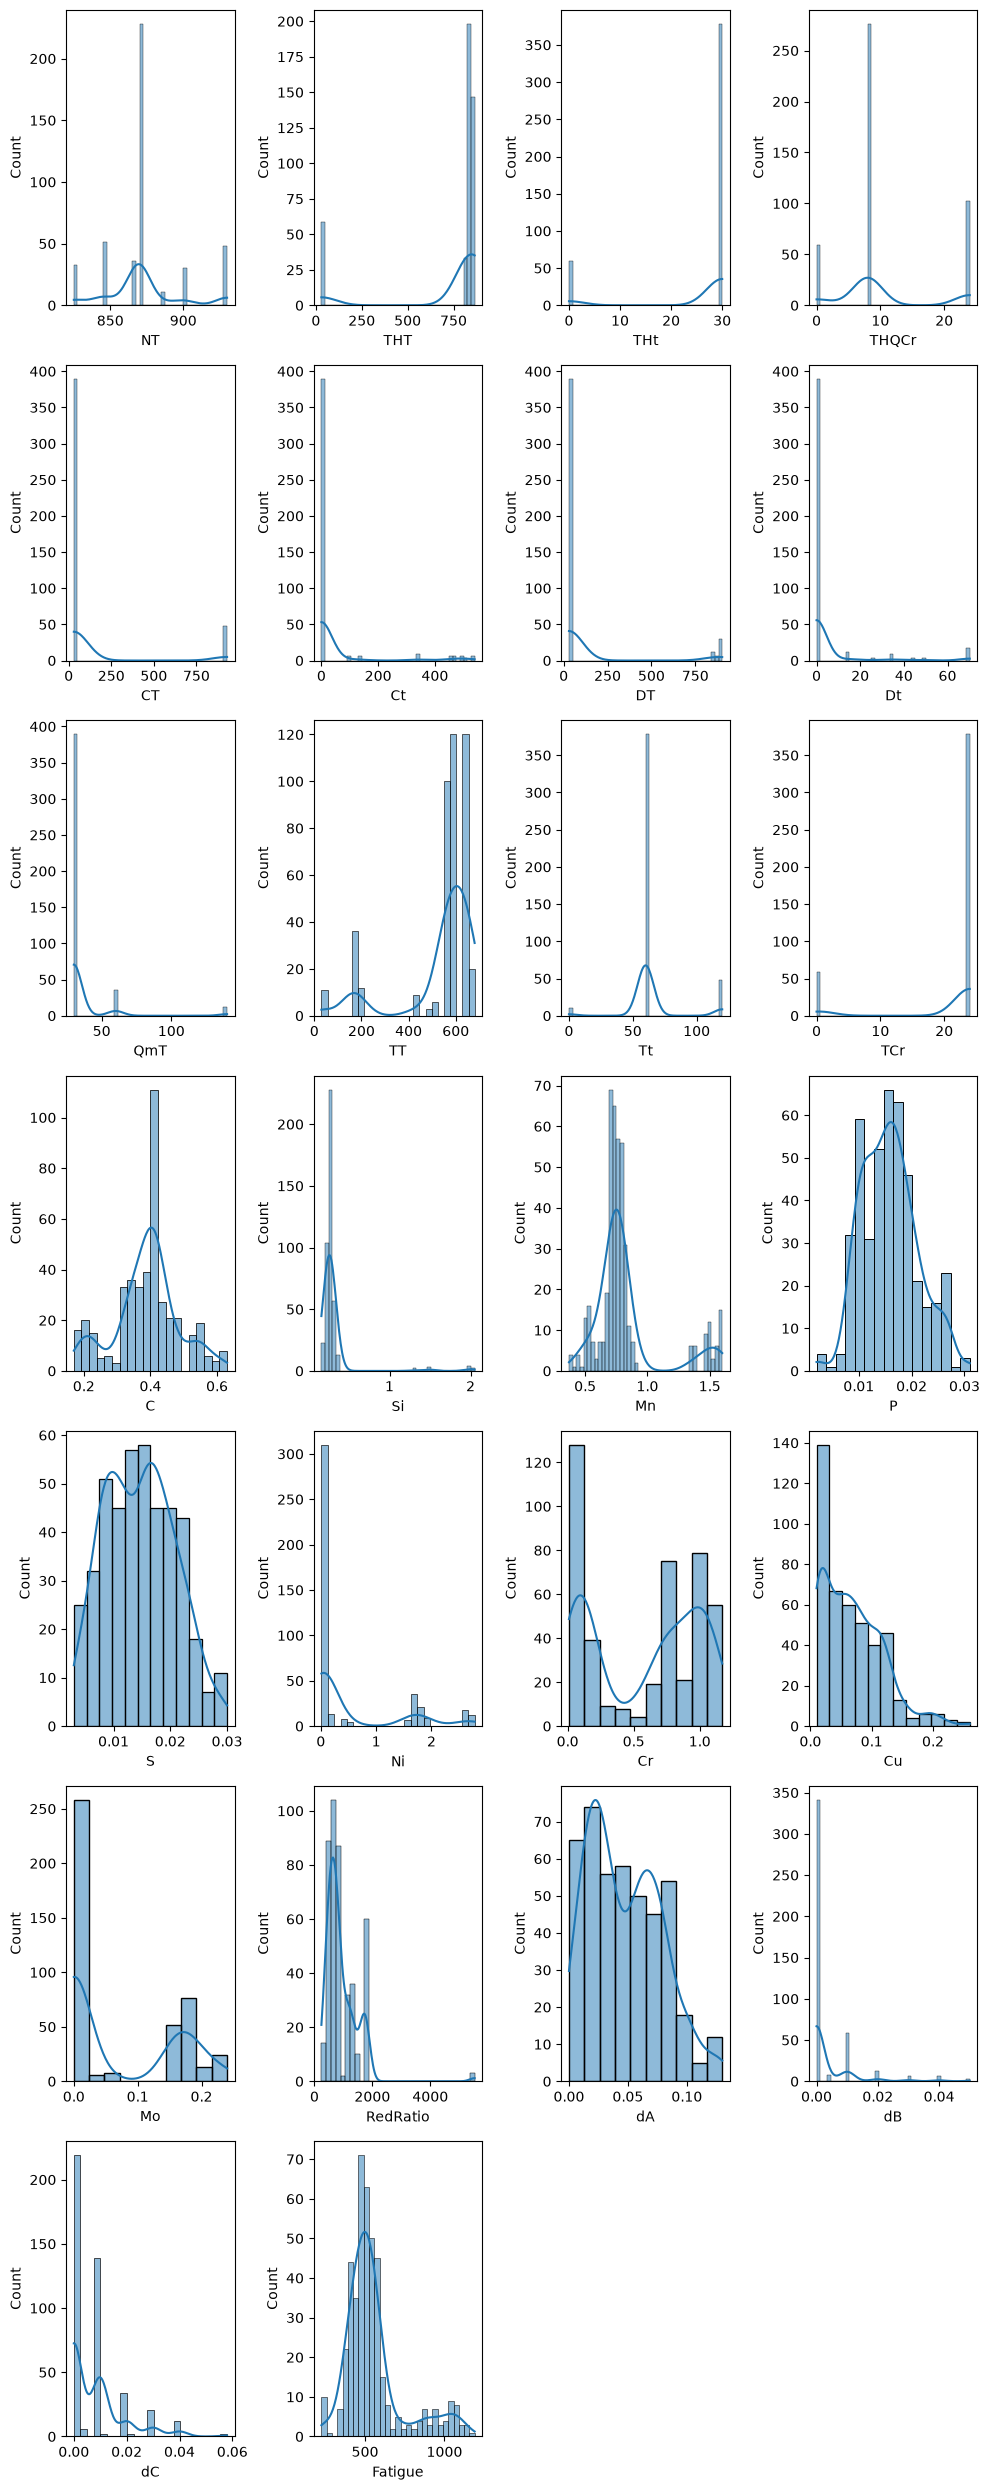

In [42]:
import seaborn as sns

features = df.columns
plt.figure(figsize=(10, 25))
for i, column in enumerate(features):
    ax = plt.subplot(len(features) // 4 + 1, 4, i + 1)
    sns.histplot(data=df, x=column, kde=True)
plt.tight_layout()
plt.show()

Lecture 4: the histogram shape depends on the bin count — two bin counts for the target.

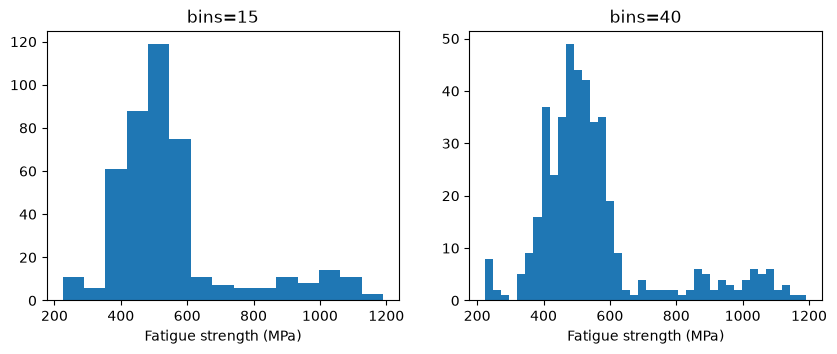

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(df['Fatigue'], bins=15); ax[0].set_title('bins=15')
ax[1].hist(df['Fatigue'], bins=40); ax[1].set_title('bins=40')
for a in ax:
    a.set_xlabel('Fatigue strength (MPa)')
plt.show()

**Result (distributions):**
- **Carburising columns (CT, Ct, DT, Dt, QmT)** all have the same two-spike shape: 389 steels at the "not done"
  value (30 °C or 0 h) and a small scatter of ~48 steels at high values. They are **categoricals in disguise**
  the main information is *carburised or not*, not the exact number.
- **Through-hardening columns (THT, THt, THQCr, TCr)** also have a spike of ~60 steels at the "not done" value
  (THT = 30, THt = 0, THQCr = 0, TCr = 0). The same count in four columns suggests they are the same ~60 steels
  (tested in Step 18).
- **Most processing columns are recipes, not continuous variables:** Tt takes only 0 / 60 / 120 min, TCr only 0 / 24,
  THQCr only 0 / 8 / 24, THt only 0 / 30. TT has a main group at 550–680 °C, a group near 170 °C and a few at 30 °C.
- **Composition is bimodal for the alloying elements:** Ni, Cr, Mo and Mn each have a group near zero
  (plain carbon steels) and a group at higher values (alloy steels); Si has a small group at 1.3–2.0 %.
  P and S are narrow, as expected for impurities. C spans 0.17–0.63 %.
- **Inclusion columns dB and dC are mostly zero** (dB = 0 for ~340 of 437 steels); RedRatio has a few isolated
  steels near 5500, far above the rest (75 % = 1228).
- **Fatigue:** main peak at 400–600 MPa (median 505, mean 553), a long right tail from ~700 to 1190 MPa where the
  carburised steels sit, and — visible only with bins = 40 — a small separate group near 230 MPa.
  With bins = 15 that low group almost disappears: the bin count changes what we see.

### Correlation matrix — Pearson r for every pair of columns

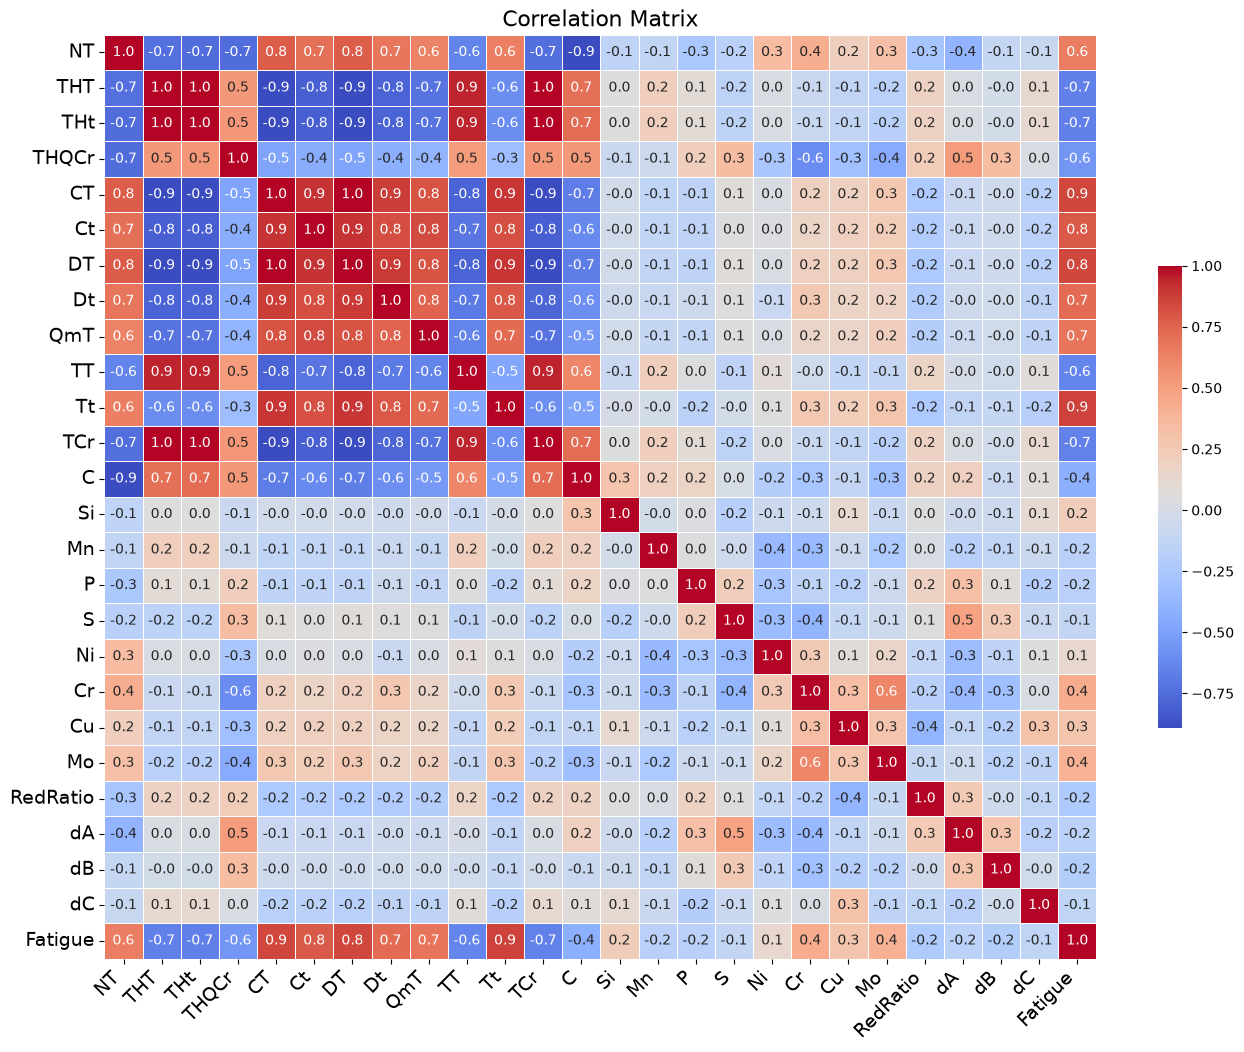

In [44]:
corr = df.corr()

f, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(corr, annot=True, ax=ax, cmap='coolwarm', fmt=".1f",
            linewidths=.5, cbar_kws={"shrink": .5})
plt.xticks(rotation=45, ha='right', fontsize=14)
plt.yticks(rotation=0, fontsize=14)
plt.title('Correlation Matrix', fontsize=16)
plt.show()

The heatmap is hard to read with 26 columns, so: (1) the strongest pairs, each pair once;
(2) the last row — Fatigue vs everything.

In [45]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna()
strong = pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False)
strong.to_frame('r')

r
THt TCr      0.999961
CT  DT       0.999700
THT THt      0.999487
    TCr      0.999448
TT  TCr      0.948144
THt TT       0.947097
THT TT       0.946717
Ct  DT       0.909506
CT  Ct       0.909458
    Tt       0.899262
DT  Tt       0.898992
NT  C       -0.889948
THt CT      -0.889131
    DT      -0.888864
THT CT      -0.888675
    DT      -0.888408
DT  Dt       0.888118
CT  TCr     -0.885035
DT  TCr     -0.884769
CT  Dt       0.879323
Tt  Fatigue  0.860337
CT  Fatigue  0.850296
DT  Fatigue  0.848612
Ct  QmT      0.832438
    Dt       0.829540
    Tt       0.817841
THt Ct      -0.808627
THT Ct      -0.808212
DT  QmT      0.807133
CT  QmT      0.806025
Ct  TCr     -0.804902

In [46]:
corr['Fatigue'].drop('Fatigue').sort_values(key=abs, ascending=False).to_frame('r with Fatigue')

,r with Fatigue
Tt,0.860337
CT,0.850296
DT,0.848612
Ct,0.778942
Dt,0.726105
QmT,0.687954
THT,-0.656615
THt,-0.655897
TCr,-0.650692
NT,0.649459


**Result (correlations):**
- **Near-exact copies (r > 0.999):** THt–TCr (0.99996), CT–DT (0.9997), THT–THt (0.9995), THT–TCr (0.9994).
  THT, THt and TCr store the same yes/no fact ("through-hardened or not") three times; CT and DT store
  "carburised or not" twice. For a linear model this is near-perfect collinearity: XᵀX close to singular,
  unstable weights.
- **Two blocks of near-copies:** the through-hardening block (THT, THt, TCr, and TT with r ≈ 0.95) and the
  carburising block (CT, DT, Ct, Dt, QmT, and Tt with r ≈ 0.82–0.90). The two blocks are negatively correlated
  (r ≈ −0.89): carburised steels are mostly not the through-hardened ones — they are different processing routes.
- **The top of the Fatigue ranking is one fact seen through six columns:** Tt (0.86), CT (0.85), DT (0.85),
  Ct (0.78), Dt (0.73), QmT (0.69) all belong to the carburising block. Tt ranks first not because tempering longer
  makes steel stronger, but because Tt = 120 min marks the same ~48 carburised steels. With a two-spike column,
  r mostly measures the difference in mean Fatigue between the two groups (≈ 507 MPa here).
- **NT–C = −0.89:** the carburised steels are low-carbon grades normalised at a high temperature (930 °C),
  so NT (r = 0.65 with Fatigue) also partly identifies the carburised group.
- **C has r = −0.41 with Fatigue:** not because carbon lowers fatigue strength, but because the strongest
  (carburised) steels are low-carbon grades that receive their carbon at the surface. Correlation is not
  mechanism.
- **Composition is only moderately correlated:** Cr 0.43, Mo 0.40, Cu 0.29; all other elements and the inclusion
  columns have |r| < 0.25.

### Step 3 — categoricals in disguise, nearly constant columns, near-copies
A table instead of eyeballing 26 histograms. Few unique values plus a most-common value of 30 or 0 →
probably a sentinel ("not done"). `frac_most_common` close to 1 → nearly constant.

In [47]:
summary = pd.DataFrame({
    'n_unique':         df.nunique(),
    'most_common':      df.mode().iloc[0],
    'frac_most_common': df.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
}).sort_values('n_unique')
summary

,n_unique,most_common,frac_most_common
THt,2,30.000,0.864989
CT,2,30.000,0.890160
THQCr,3,8.000,0.631579
QmT,3,30.000,0.890160
Tt,3,60.000,0.864989
TCr,3,24.000,0.864989
THT,5,845.000,0.453089
NT,7,870.000,0.521739
DT,7,30.000,0.890160
Dt,7,0.000,0.890160


**Result (summary table):**
- **Pure flags written as numbers:** CT has only 2 values (30 / 930 °C) and THt only 2 (0 / 30 min) — they carry
  no information beyond yes/no. Tt, TCr, THQCr and QmT have only 3 values each: recipes, not continuous variables.
- **The fractions are route sizes:** 0.864989 = 378/437 for THt, Tt and TCr (the through-hardened steels);
  0.890160 = 389/437 for CT, Ct, DT, Dt and QmT (the non-carburised steels). Columns with the same fraction
  describe the same group of steels.
- **Mostly-zero columns:** dB (78 % zero), Mo (57 %), dC (50 %). They are not constant, but most of the
  information is "present or not".
- **Truly continuous columns:** the composition (C, Si, Mn, P, S, Ni, Cr, Cu: 21–65 unique values, no value
  shared by more than 16 % of steels), dA, RedRatio, and the target Fatigue (250 unique values).

Do the "not done" values of the different processing groups belong to the same steels?
If so, the 25 processing + composition columns hide a few **processing routes** — a categorical variable.

In [48]:
flags = pd.DataFrame({
    'carburised':       df['CT'] > 30,
    'through_hardened': df['THT'] > 30,
    'tempered':         df['TT'] > 30,
})
pd.crosstab(flags['carburised'], flags['through_hardened'])

through_hardened,False,True
carburised,,
False,11,378
True,48,0


In [49]:
df.groupby([flags['carburised'], flags['through_hardened'], flags['tempered']]).Fatigue.agg(['size', 'mean'])

size         mean
carburised through_hardened tempered                   
False      False            False       11   243.818182
           True             True       378   504.597884
True       False            True        48  1004.145833

**Result (processing routes):** The processing columns encode exactly **three routes** — a hidden categorical variable:

| Route | carburised | through-hardened | tempered | steels | mean Fatigue |
|---|---|---|---|---|---|
| A: normalised only | no | no | no | 11 | 244 MPa |
| B: through-hardened + tempered | no | yes | yes | 378 | 505 MPa |
| C: carburised + tempered | yes | no | yes | 48 | 1004 MPa |

No steel is both carburised and through-hardened. This explains the correlation matrix: the through-hardening
block and the carburising block are negatively correlated because they are mutually exclusive routes, and the
three groups in the Fatigue histogram (≈ 230, 400–600 and 850–1190 MPa) are the three routes.
The route alone explains most of the spread in Fatigue; the 12 processing columns are mostly 12 noisy ways
of writing down one categorical variable with 3 values. The correct encoding is one-hot:
two 0/1 columns are enough (e.g. `route_B`, `route_C`, with A as the reference), plus the real process
parameters *within* a route where they vary.

### Step 4 — building the proposed descriptor set
The processing route becomes one categorical column, then one-hot encoded. Route A is the reference:
with an intercept in the model, `route_A + route_B + route_C = 1` for every steel, so keeping all three would make
the columns of X linearly dependent (XᵀX singular). Two flags carry the full information.

In [50]:
df['route'] = np.select([flags['carburised'], flags['through_hardened']], ['C', 'B'], default='A')
print(df['route'].value_counts())

dummies = pd.get_dummies(df['route'], prefix='route', dtype=int).drop(columns='route_A')

descriptors = ['C', 'Si', 'Mn', 'P', 'S', 'Ni', 'Cr', 'Cu', 'Mo',
               'NT', 'THQCr', 'TT', 'Ct',
               'RedRatio', 'dA', 'dB', 'dC']
X_desc = pd.concat([df[descriptors], dummies], axis=1)
print(X_desc.shape)

# Check: is the collinearity gone? strongest remaining pairs
c = X_desc.corr()
top = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().dropna()
top.sort_values(key=abs, ascending=False).head(8).to_frame('r')

route
B    378
C     48
A     11
Name: count, dtype: int64
(437, 19)


r
TT      route_B  0.947097
Ct      route_C  0.909458
C       NT      -0.889948
route_B route_C -0.889131
Ct      route_B -0.808627
TT      route_C -0.786156
NT      route_C  0.774140
        THQCr   -0.746162

**Remaining collinearity check.** After replacing the 8 flag columns by route_B / route_C, no pair has
r > 0.95 (the r > 0.999 copies are gone). Four strong pairs remain, each with a physical cause:
- **TT – route_B (0.947), Ct – route_C (0.909):** most of the variation in TT and Ct is *between* routes, not within
  them, so their within-route slopes will be estimated with less precision. A possible fix for Friday: centre TT and
  Ct within their route (subtract the route mean), which makes them uncorrelated with the route flags.
- **route_B – route_C (−0.889):** unavoidable — the reference route A has only 11 steels, so the intercept rests on
  11 rows. Results for route A should be read with caution.
- **C – NT (−0.890):** the carburising grades are low-carbon steels normalised at 930 °C. Keep both for now and
  check whether their weights are stable when the model is fitted.

### Observations
1. **Target.** Fatigue has mean 553 MPa but median 505 MPa, and max 1190 vs 75 % = 578 MPa: a long right tail.
   With bins = 40 the histogram shows three groups (≈ 230, 400–600, 850–1190 MPa).
2. **Categoricals in disguise.** The processing columns encode **three processing routes**:
   A normalised only (11 steels, mean 244 MPa), B through-hardened + tempered (378, 505 MPa),
   C carburised + tempered (48, 1004 MPa). No steel is both carburised and through-hardened.
   Sentinels: 30 °C / 0 h mean "not done" (CT, DT, QmT, THT, TT = 30; Ct, Dt, THt, THQCr, TCr, Tt = 0).
   CT and THt take only two values each — they are yes/no flags written as numbers.
3. **Nearly constant / recipe columns.** Tt (0/60/120), TCr (0/24), THQCr (0/8/24), THt (0/30) are recipes;
   within a route most of them are constant. dB, dC and Mo are mostly zero.
4. **Near-copy groups.** THT–THt–TCr (r > 0.999) and CT–DT (r = 0.9997) are the same yes/no fact stored several
   times; the through-hardening block (THT, THt, TCr, TT) and the carburising block (CT, DT, Ct, Dt, QmT, Tt) are
   each internally correlated at 0.8–1.0 and negatively correlated with each other (≈ −0.89) because the routes
   are mutually exclusive. In OLS this would make XᵀX nearly singular.
5. **Surprises.** Tt has the highest r with Fatigue (0.86) only because Tt = 120 min marks the carburised steels.
   C has r = −0.41 because the strongest (carburised) steels are low-carbon grades that receive carbon at the surface;
   NT–C = −0.89 for the same reason. Correlation is not mechanism.

### Proposed descriptors for a linear model of Fatigue (19 columns)
Reasons in the order physics → distribution → correlation.

| Column(s) | Decision | Justification |
|---|---|---|
| **route_B, route_C** (new) | **keep** (replace 8 columns) | Physics: the processing route sets the microstructure and surface state. Distribution: the processing columns are two-spike/recipe columns. Correlation: they are near-copies; two one-hot flags carry the same information without collinearity or a fake order. |
| CT, DT, THt, TCr | drop | Each is a yes/no flag (or constant within a route) — fully replaced by route_B / route_C. |
| THT | drop | Within route B it only varies 845–865 °C (5 values); otherwise it is the through-hardening flag. |
| Tt | drop | Constant within each route (0 / 60 / 120) → it is the route flag again; r = 0.86 is the carburising effect, not tempering time. |
| Dt, QmT | drop | Inside route C they are near-copies of Ct (r ≈ 0.83); with only 48 carburised steels, one carburising parameter is enough. |
| **Ct** | **keep** | Carburising time controls case depth — the physical reason carburised steels resist fatigue. 0 h for non-carburised steels is a true value. |
| **TT** | **keep** | Physics: higher tempering temperature → softer, lower-strength steel → expected **negative** effect on Fatigue (r = −0.63). Varies 550–680 °C within route B. |
| **THQCr** | **keep** | Quenching cooling rate (8 or 24 within route B) controls how fully the steel hardens. |
| **NT** | **keep, with a warning** | A real temperature (825–930 °C); but strongly correlated with C (−0.89) — check the weight's stability when fitting. |
| **C, Si, Mn, Ni, Cr, Cu, Mo** | **keep** | Composition sets hardenability and strength; continuous with 15–65 distinct values. C's negative r is confounded by the route — with route flags in the model, C's own effect can be estimated. |
| **P, S** | **keep** | Low r (< 0.2) is not a reason to drop: S forms MnS inclusions and P embrittles grain boundaries — both are physical fatigue mechanisms. Narrow ranges, but only 2 columns. |
| **RedRatio** | **keep** | Higher reduction ratio → finer structure and smaller inclusions. Long right tail (max 5530 vs 75 % = 1228): consider a log transform later. |
| **dA, dB, dC** | **keep** | Inclusions are crack-initiation sites in fatigue. dB and dC are mostly zero, but the nonzero values are physically meaningful. |

**Why the "not done" values of kept parameters (e.g. Ct = 0, THQCr = 0, TT = 30) are acceptable:** inside routes A and C
they are constant, so the route flags and the intercept absorb them. The slope of each kept parameter is then learned
from the steels where the treatment was actually applied.